In [19]:
#Import libraries
import pandas as pd
import numpy as np
import joblib
import os

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)


# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

print("All libraries imported successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
All libraries imported successfully!


In [20]:
#Load Processed Datasets
# Artifacts folder path
folder = '/content/drive/MyDrive/Diabetes-Prediction/artifacts'

# Load datasets
X_train = pd.read_csv(os.path.join(folder, 'X_train_processed.csv'))
X_test = pd.read_csv(os.path.join(folder, 'X_test_processed.csv'))

y_train = pd.read_csv(os.path.join(folder, 'y_train.csv')).squeeze()
y_test = pd.read_csv(os.path.join(folder, 'y_test.csv')).squeeze()

print("All datasets loaded successfully!")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

All datasets loaded successfully!
X_train: (16000, 21)
X_test: (4000, 21)
y_train: (16000,)
y_test: (4000,)


In [21]:
#Train SVM Model
model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    random_state=42
)

model.fit(X_train, y_train)

print("SVM model training completed!")

SVM model training completed!


In [22]:
#5-Fold Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=['accuracy', 'precision', 'recall', 'f1']
)

print("5-Fold Cross-Validation Results")

print("Accuracy:", scores['test_accuracy'].mean())
print("Precision:", scores['test_precision'].mean())
print("Recall:", scores['test_recall'].mean())
print("F1-Score:", scores['test_f1'].mean())

5-Fold Cross-Validation Results
Accuracy: 0.974375
Precision: 0.9810933643850251
Recall: 0.9884164669082194
F1-Score: 0.9847389683400035


In [23]:
#Make predictions
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[1 1 1 1 0 1 0 1 0 1]

Predicted Values:
[1 1 1 1 0 1 0 1 0 1]


In [24]:
#Evaluate Model Performance
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

balanced_acc = balanced_accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)
print("Balanced Accuracy:", balanced_acc)

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Non-diabetic", "Diabetic"],
    zero_division=0
))

Accuracy: 0.976
Precision: 0.9821905609973286
Recall: 0.989237668161435
F1-Score: 0.9857015192135835
Balanced Accuracy: 0.9488173073631603

Classification Report:
              precision    recall  f1-score   support

Non-diabetic       0.94      0.91      0.93       655
    Diabetic       0.98      0.99      0.99      3345

    accuracy                           0.98      4000
   macro avg       0.96      0.95      0.96      4000
weighted avg       0.98      0.98      0.98      4000



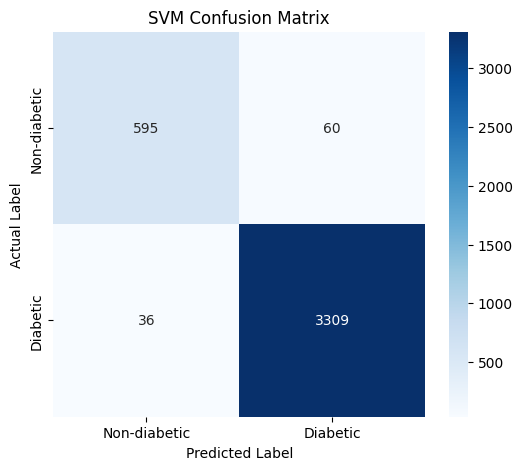

True Negatives: 595
False Positives: 60
False Negatives: 36
True Positives: 3309
Specificity: 0.9083969465648855


In [25]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-diabetic', 'Diabetic'],
    yticklabels=['Non-diabetic', 'Diabetic']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp) if (tn + fp) else 0

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)
print("Specificity:", specificity)

In [26]:
#Save Trained Model
MODEL_PATH = '/content/drive/MyDrive/Diabetes-Prediction/artifacts/svm (8).joblib'

joblib.dump(model, MODEL_PATH)

print("Model saved successfully!")
print("Saved Location:", MODEL_PATH)

Model saved successfully!
Saved Location: /content/drive/MyDrive/Diabetes-Prediction/artifacts/svm (8).joblib


In [27]:
#Save Evaluation Metrics
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Balanced Accuracy": balanced_acc,
    "Specificity": specificity
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Score"]
)

display(metrics_df.round(4))

metrics_df.to_csv(
    os.path.join(folder, 'svm_metrics.csv'),
    index=False
)

print("Evaluation metrics saved successfully!")

,Metric,Score
0,Accuracy,0.9760
1,Precision,0.9822
2,Recall,0.9892
3,F1-score,0.9857
4,Balanced Accuracy,0.9488
5,Specificity,0.9084


Evaluation metrics saved successfully!
